# Laksa Custom CNN — klasifikasi keparahan jerawat (IGA / GEA)

Notebook ini melatih **custom CNN** untuk klasifikasi tingkat keparahan jerawat memakai dataset Roboflow:

**Acne Severity Classification v3** — [Taschenbier / Universe](https://universe.roboflow.com/taschenbier/acne-severity-classification/dataset/3)

Alur: **API key `.env` → unduh v3 → `tf.data` → CNN → evaluasi → mapping IGA→GEA → ekspor TFLite**.

Dataset v3 berisi ~6.451 gambar (train 5.991 / valid 325 / test 135) dengan kelas **IGA**: `IGA0`, `IGA1`, `IGA2`, `IGA3`, `IGA3_Level3`, `IGA4`. Skala IGA dekat dengan **GEA 0–5** yang ditampilkan aplikasi.

Isi `ROBOFLOW_API_KEY` di `machine-learning/.env` (jangan commit file itu). Salin dari `.env.example` jika belum ada.


## 1. Dependensi

`tensorflow` untuk CNN. `roboflow` mengunduh dataset lewat API. `python-dotenv` membaca kunci dari `.env`. Setelah install, **restart kernel** lalu jalankan lagi dari sel import.


In [1]:
import sys
print("Python:", sys.version)
print("Executable:", sys.executable)

%pip install --upgrade pip
%pip install "tensorflow>=2.15,<2.20" "roboflow>=1.1" "python-dotenv>=1.0" scikit-learn pillow matplotlib tqdm numpy

import tensorflow as tf
print("TensorFlow:", tf.__version__)


Python: 3.10.6 (tags/v3.10.6:9c7b4bd, Aug  1 2022, 21:53:49) [MSC v.1932 64 bit (AMD64)]
Executable: c:\laragon\bin\python\python-3.10\python.exe
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
TensorFlow: 2.19.1


## 2. Import, seed, dan perangkat


In [2]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from dotenv import load_dotenv
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
)
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import layers, regularizers

SEED = 42
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.19.1
GPU: []


## 3. Lokasi proyek, API key, dan konfigurasi

Notebook mencari folder `machine-learning/` (tempat `.env` dan `dataset/`), baik dijalankan dari `notebooks/` maupun dari root folder ML.

Kunci API **tidak** ditulis di sel. Kalau error, pastikan `machine-learning/.env` berisi `ROBOFLOW_API_KEY=...`.


In [3]:
cwd = Path.cwd().resolve()
kandidat = [cwd, cwd.parent, cwd / "machine-learning"]
ML_ROOT = next((p for p in kandidat if (p / ".env").exists()), None)
if ML_ROOT is None:
    raise FileNotFoundError(
        "Tidak menemukan machine-learning/.env. "
        "Jalankan notebook dari folder machine-learning atau notebooks/."
    )

load_dotenv(ML_ROOT / ".env", override=True)
api_key = os.environ.get("ROBOFLOW_API_KEY", "").strip()
if not api_key:
    raise ValueError("ROBOFLOW_API_KEY kosong. Isi machine-learning/.env")

UKURAN = 224
BATCH_SIZE = 32
EPOCHS = 40
ROBOFLOW_PROJECT = "acne-severity-classification"
ROBOFLOW_VERSION = 3
ROBOFLOW_UNIVERSE_WORKSPACE = "taschenbier"

NAMA_KELAS = ["IGA0", "IGA1", "IGA2", "IGA3", "IGA3_Level3", "IGA4"]
LABEL_GEA = {
    "IGA0": {"grade": 0, "label": "Bersih / Clear"},
    "IGA1": {"grade": 1, "label": "Hampir bersih / Almost clear"},
    "IGA2": {"grade": 2, "label": "Ringan / Mild"},
    "IGA3": {"grade": 3, "label": "Sedang / Moderate"},
    "IGA3_Level3": {"grade": 3, "label": "Sedang / Moderate (IGA3 Level 3)"},
    "IGA4": {"grade": 4, "label": "Berat / Severe"},
}

folder_dataset = ML_ROOT / "dataset" / f"{ROBOFLOW_PROJECT}-{ROBOFLOW_VERSION}"
folder_laporan = ML_ROOT / "laksamanaap"
folder_hasil = ML_ROOT / "runs" / "laksa_custom_cnn"
folder_laporan.mkdir(parents=True, exist_ok=True)
folder_hasil.mkdir(parents=True, exist_ok=True)
path_keras = folder_hasil / "model_terbaik.keras"
path_tflite = folder_laporan / "laksa_custom_cnn.tflite"

print("ML_ROOT:", ML_ROOT)
print("Dataset:", folder_dataset)
print("Hasil training:", folder_hasil)
print("Export TFLite:", path_tflite)


ML_ROOT: D:\Kuliah\Smt 5\PBL\PBL-Skin-Problem-Detector\machine-learning
Dataset: D:\Kuliah\Smt 5\PBL\PBL-Skin-Problem-Detector\machine-learning\dataset\acne-severity-classification-3
Hasil training: D:\Kuliah\Smt 5\PBL\PBL-Skin-Problem-Detector\machine-learning\runs\laksa_custom_cnn
Export TFLite: D:\Kuliah\Smt 5\PBL\PBL-Skin-Problem-Detector\machine-learning\models\laksa_custom_cnn.tflite


## 4. Unduh dataset v3 lewat Roboflow API

Format `folder` menghasilkan `train/`, `valid/`, `test/` dengan subfolder per kelas. Unduhan dilewati jika folder itu sudah ada.

Proyek publik asalnya milik workspace `taschenbier`. Kalau sudah di-fork ke workspace akunmu, SDK memakai workspace default dari API key.


In [4]:
from roboflow import Roboflow


def folder_split_siap(akar: Path) -> bool:
    pecahan = [p for p in ("train", "valid", "val", "test") if (akar / p).is_dir()]
    return len(pecahan) >= 2


if folder_split_siap(folder_dataset):
    print("Dataset v3 sudah ada, skip download:", folder_dataset)
else:
    rf = Roboflow(api_key=api_key)
    project = None
    try:
        project = rf.workspace().project(ROBOFLOW_PROJECT)
        print("Pakai workspace akun:", project.id)
    except Exception as gagal_lokal:
        print("Proyek tidak ada di workspace akun:", gagal_lokal)
        project = rf.workspace(ROBOFLOW_UNIVERSE_WORKSPACE).project(ROBOFLOW_PROJECT)
        print("Pakai Universe:", project.id)

    versi = project.version(ROBOFLOW_VERSION)
    print("Mengunduh versi", ROBOFLOW_VERSION, "ke", folder_dataset)
    versi.download("folder", location=str(folder_dataset), overwrite=False)
    print("Selesai unduh:", folder_dataset)

assert folder_split_siap(folder_dataset), f"Struktur folder dataset tidak lengkap: {folder_dataset}"


loading Roboflow workspace...
loading Roboflow project...
Pakai workspace akun: laksamana-aryaputra/acne-severity-classification
Mengunduh versi 3 ke D:\Kuliah\Smt 5\PBL\PBL-Skin-Problem-Detector\machine-learning\dataset\acne-severity-classification-3



Extracting Dataset Version Zip to D:\Kuliah\Smt 5\PBL\PBL-Skin-Problem-Detector\machine-learning\dataset\acne-severity-classification-3 in folder:: 100%|██████████| 6471/6471 [00:05<00:00, 1232.72it/s]


Selesai unduh: D:\Kuliah\Smt 5\PBL\PBL-Skin-Problem-Detector\machine-learning\dataset\acne-severity-classification-3


## 5. Inventarisasi kelas dan pecahan data

Kelas `IGA3_Level3` pada sumber asli bisa kosong. Sel ini hanya menghitung folder yang benar-benar berisi gambar.


In [5]:
def daftar_gambar(folder: Path):
    return [
        p
        for p in folder.rglob("*")
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]


pecahan_nama = []
for nama in ("train", "valid", "val", "test"):
    if (folder_dataset / nama).is_dir():
        pecahan_nama.append("valid" if nama == "val" else nama)

# Roboflow kadang memakai "valid"; samakan ke valid
if (folder_dataset / "val").is_dir() and not (folder_dataset / "valid").is_dir():
    (folder_dataset / "val").rename(folder_dataset / "valid")
    pecahan_nama = ["valid" if n == "val" else n for n in pecahan_nama]

print("Pecahan:", pecahan_nama)
print()

hitung = {}
for pecahan in pecahan_nama:
    akar = folder_dataset / pecahan
    hitung[pecahan] = {}
    print(f"=== {pecahan} ===")
    for kelas_dir in sorted([p for p in akar.iterdir() if p.is_dir()]):
        n = len(daftar_gambar(kelas_dir))
        hitung[pecahan][kelas_dir.name] = n
        print(f"  {kelas_dir.name:16s} {n:5d}")
    print("  total", sum(hitung[pecahan].values()))
    print()

kelas_terpakai = sorted(
    {nama for pecahan in hitung.values() for nama, n in pecahan.items() if n > 0}
)
print("Kelas terpakai:", kelas_terpakai)
if "IGA3_Level3" not in kelas_terpakai:
    print("Catatan: IGA3_Level3 tidak punya gambar — kelas ini diabaikan saat training.")


Pecahan: ['train', 'valid', 'test']

=== train ===
  IGA0              1113
  IGA1              1257
  IGA2              2730
  IGA3               501
  IGA4               390
  total 5991

=== valid ===
  IGA0                78
  IGA1                48
  IGA2               136
  IGA3                34
  IGA4                29
  total 325

=== test ===
  IGA0                30
  IGA1                20
  IGA2                58
  IGA3                16
  IGA4                11
  total 135

Kelas terpakai: ['IGA0', 'IGA1', 'IGA2', 'IGA3', 'IGA4']
Catatan: IGA3_Level3 tidak punya gambar — kelas ini diabaikan saat training.


## 6. `tf.data` dari folder

Gambar di-resize ke 224×224. Label integer mengikuti urutan folder (alfabetis: IGA0 … IGA4). Augmentasi ada di dalam model, bukan di pipeline ini, agar validation/test bersih.


In [6]:
def muat_pecahan(nama: str, shuffle: bool):
    return tf.keras.utils.image_dataset_from_directory(
        folder_dataset / nama,
        labels="inferred",
        label_mode="int",
        image_size=(UKURAN, UKURAN),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
        interpolation="bilinear",
        color_mode="rgb",
    )


train_ds = muat_pecahan("train", shuffle=True)
val_ds = muat_pecahan("valid", shuffle=False)
test_ds = muat_pecahan("test", shuffle=False)

nama_kelas = list(train_ds.class_names)
jumlah_kelas = len(nama_kelas)
indeks_kelas = {nama: i for i, nama in enumerate(nama_kelas)}

autotune = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(autotune)
val_ds = val_ds.prefetch(autotune)
test_ds = test_ds.prefetch(autotune)

print("Urutan kelas:", nama_kelas)
print("Jumlah kelas:", jumlah_kelas)


Found 5991 files belonging to 5 classes.
Found 325 files belonging to 5 classes.
Found 135 files belonging to 5 classes.
Urutan kelas: ['IGA0', 'IGA1', 'IGA2', 'IGA3', 'IGA4']
Jumlah kelas: 5


## 7. Bobot kelas dan contoh gambar

Kelas IGA2 biasanya dominan. `class_weight="balanced"` menaikkan kontribusi kelas yang lebih jarang (IGA3, IGA4) pada loss.


Distribusi train: {'IGA0': np.int64(1113), 'IGA1': np.int64(1257), 'IGA2': np.int64(2730), 'IGA3': np.int64(501), 'IGA4': np.int64(390)}
Class weight: {'IGA0': 1.077, 'IGA1': 0.953, 'IGA2': 0.439, 'IGA3': 2.392, 'IGA4': 3.072}


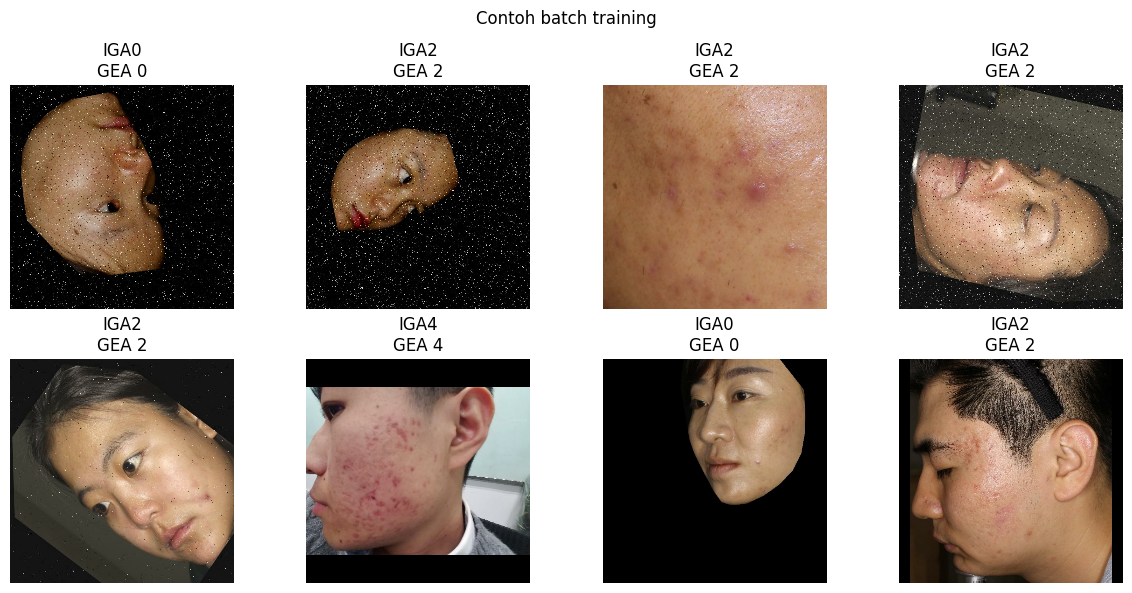

In [7]:
y_train = np.concatenate([y.numpy() for _, y in train_ds], axis=0)
bobot = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(jumlah_kelas),
    y=y_train,
)
class_weight = {int(i): float(w) for i, w in enumerate(bobot)}
print("Distribusi train:", dict(zip(nama_kelas, np.bincount(y_train))))
print("Class weight:", {nama_kelas[i]: round(w, 3) for i, w in class_weight.items()})

gambar_batch, label_batch = next(iter(train_ds))
plt.figure(figsize=(12, 6))
for i in range(min(8, gambar_batch.shape[0])):
    ax = plt.subplot(2, 4, i + 1)
    ax.imshow(gambar_batch[i].numpy().astype("uint8"))
    idx = int(label_batch[i])
    gea = LABEL_GEA.get(nama_kelas[idx], {})
    ax.set_title(f"{nama_kelas[idx]}\nGEA {gea.get('grade', '?')}")
    ax.axis("off")
plt.suptitle("Contoh batch training")
plt.tight_layout()
plt.show()


## 8. Arsitektur custom CNN

Empat blok `Conv2D → BatchNorm → ReLU` (filter 32, 64, 128, 128), pooling pada tiga blok pertama, Global Average Pooling, Dropout 0.3, Softmax sejumlah kelas IGA. Input masih 0–255; `Rescaling(1/255)` ada di dalam model supaya export TFLite tidak perlu normalisasi terpisah.


In [8]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

inputs = layers.Input(shape=(UKURAN, UKURAN, 3), name="gambar")
x = layers.Rescaling(1.0 / 255)(inputs)
x = layers.RandomFlip("horizontal")(x)
x = layers.RandomRotation(factor=0.03, fill_mode="reflect")(x)

for i, jumlah_filter in enumerate([32, 64, 128, 128]):
    x = layers.Conv2D(
        filters=jumlah_filter,
        kernel_size=3,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal",
        kernel_regularizer=regularizers.l2(1e-4),
        name=f"conv_{i + 1}",
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    if i < 3:
        x = layers.MaxPooling2D(pool_size=2)(x)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(jumlah_kelas, activation="softmax", name="severity")(x)

model = tf.keras.Model(inputs, outputs, name="Laksa_CustomCNN_IGA")
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()
print("Jumlah parameter:", model.count_params())


Model: "Laksa_CustomCNN_IGA"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gambar (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_4 (Conv2D)                 │ (None, 28, 28, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ severity (Dense)                │ (None, 5)              │           64

 Total params: 242,533 (947.39 KB)

 Trainable params: 241,829 (944.64 KB)

 Non-trainable params: 704 (2.75 KB)

Jumlah parameter: 242533


## 9. Callback

Checkpoint disimpan saat **validation macro-F1** naik. Early stopping 12 epoch; learning rate dipotong jika macet 4 epoch.


In [9]:
class HitungMacroF1(tf.keras.callbacks.Callback):
    def __init__(self, val_ds, nama_kelas):
        super().__init__()
        self.val_ds = val_ds
        self.nama_kelas = nama_kelas
        self.y_val = np.concatenate([y.numpy() for _, y in val_ds], axis=0)

    def on_epoch_end(self, epoch, logs=None):
        probabilitas = self.model.predict(self.val_ds, verbose=0)
        prediksi = np.argmax(probabilitas, axis=1)
        skor = f1_score(
            self.y_val,
            prediksi,
            labels=list(range(len(self.nama_kelas))),
            average="macro",
            zero_division=0,
        )
        if logs is not None:
            logs["val_macro_f1"] = skor
        print(f" — val_macro_f1: {skor:.4f}")


callbacks = [
    HitungMacroF1(val_ds, nama_kelas),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(path_keras),
        monitor="val_macro_f1",
        mode="max",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_macro_f1",
        mode="max",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_macro_f1",
        mode="max",
        patience=12,
        restore_best_weights=False,
        verbose=1,
    ),
    tf.keras.callbacks.CSVLogger(str(folder_hasil / "riwayat_training.csv")),
]


## 10. Training


In [10]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks,
)

model_terbaik = tf.keras.models.load_model(path_keras, compile=False)
print("Model terbaik:", path_keras)


Epoch 1/40
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 813ms/step - accuracy: 0.3140 - loss: 1.5600 — val_macro_f1: 0.2888

Epoch 1: val_macro_f1 improved from None to 0.28880, saving model to D:\Kuliah\Smt 5\PBL\PBL-Skin-Problem-Detector\machine-learning\runs\laksa_custom_cnn\model_terbaik.keras
188/188 ━━━━━━━━━━━━━━━━━━━━ 159s 832ms/step - accuracy: 0.3467 - loss: 1.4504 - val_accuracy: 0.3354 - val_loss: 1.4798 - val_macro_f1: 0.2888 - learning_rate: 0.0010
Epoch 2/40
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 831ms/step - accuracy: 0.3868 - loss: 1.3367 — val_macro_f1: 0.4076

Epoch 2: val_macro_f1 improved from 0.28880 to 0.40764, saving model to D:\Kuliah\Smt 5\PBL\PBL-Skin-Problem-Detector\machine-learning\runs\laksa_custom_cnn\model_terbaik.keras
188/188 ━━━━━━━━━━━━━━━━━━━━ 160s 848ms/step - accuracy: 0.3801 - loss: 1.3159 - val_accuracy: 0.4185 - val_loss: 1.3481 - val_macro_f1: 0.4076 - learning_rate: 0.0010
Epoch 3/40
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 830ms/step - accuracy: 0.3955 - loss: 1.2996 —

## 11. Kurva pembelajaran


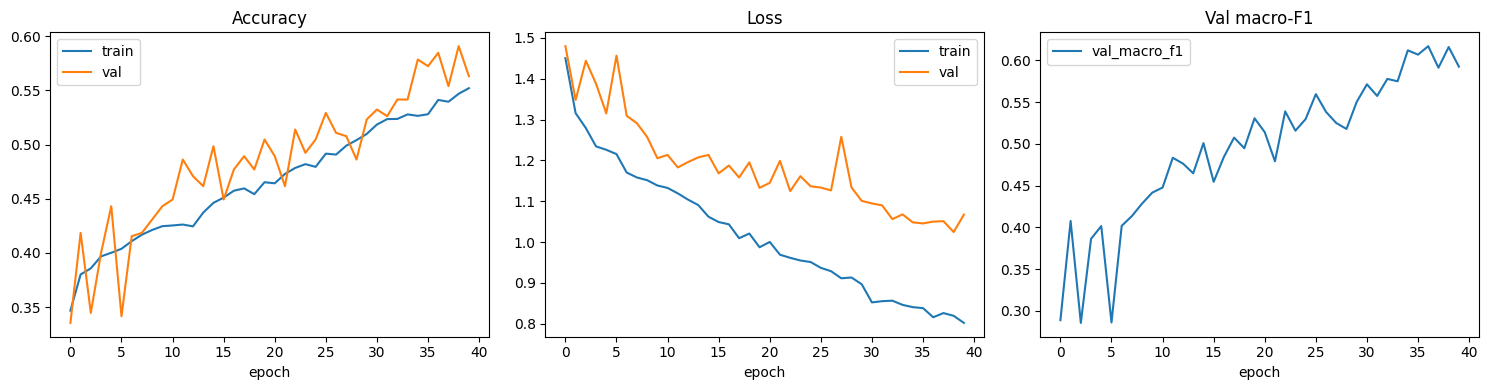

In [11]:
riwayat = history.history
epoch_idx = range(len(riwayat["loss"]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(epoch_idx, riwayat["accuracy"], label="train")
axes[0].plot(epoch_idx, riwayat["val_accuracy"], label="val")
axes[0].set_title("Accuracy")
axes[0].legend()

axes[1].plot(epoch_idx, riwayat["loss"], label="train")
axes[1].plot(epoch_idx, riwayat["val_loss"], label="val")
axes[1].set_title("Loss")
axes[1].legend()

if "val_macro_f1" in riwayat:
    axes[2].plot(epoch_idx, riwayat["val_macro_f1"], label="val_macro_f1")
    axes[2].set_title("Val macro-F1")
    axes[2].legend()

for ax in axes:
    ax.set_xlabel("epoch")
plt.tight_layout()
plt.savefig(folder_hasil / "kurva_pembelajaran.png", dpi=120)
plt.show()


## 12. Evaluasi test set

Macro-F1 memperlakukan setiap kelas IGA setara. MAE dihitung pada indeks kelas (IGA berurutan), sebagai gambaran seberapa jauh prediksi dari grade sebenarnya.



===== Validation =====
              precision    recall  f1-score   support

        IGA0       0.61      0.79      0.69        78
        IGA1       0.52      0.79      0.63        48
        IGA2       0.68      0.25      0.37       136
        IGA3       0.48      0.94      0.64        34
        IGA4       0.71      0.83      0.76        29

    accuracy                           0.58       325
   macro avg       0.60      0.72      0.62       325
weighted avg       0.62      0.58      0.55       325

macro-F1: 0.6168968444393664
MAE (indeks kelas): 0.6430769230769231


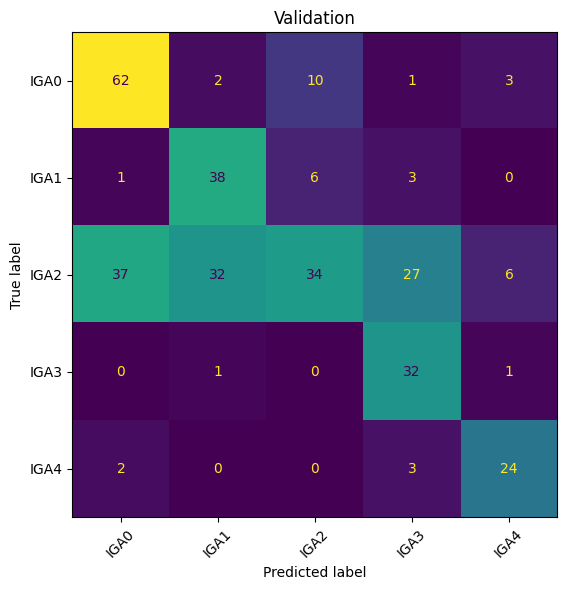


===== Test =====
              precision    recall  f1-score   support

        IGA0       0.54      0.87      0.67        30
        IGA1       0.53      0.85      0.65        20
        IGA2       0.67      0.17      0.27        58
        IGA3       0.50      0.69      0.58        16
        IGA4       0.61      1.00      0.76        11

    accuracy                           0.56       135
   macro avg       0.57      0.72      0.59       135
weighted avg       0.59      0.56      0.49       135

macro-F1: 0.5864106962657543
MAE (indeks kelas): 0.6814814814814815


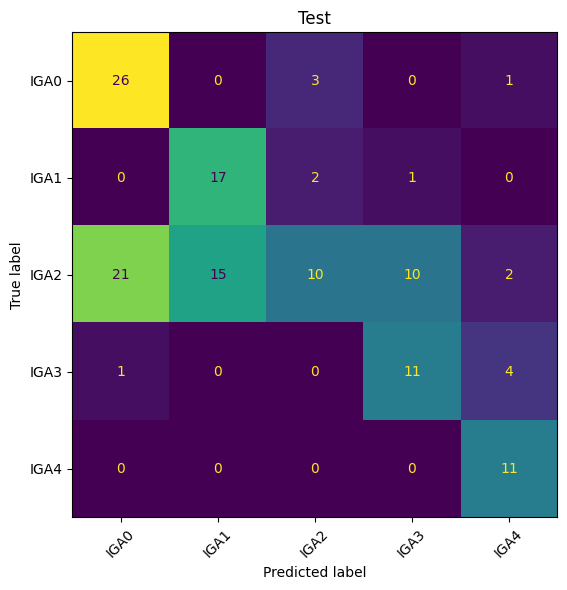

In [12]:
def evaluasi(ds, judul):
    y_true = np.concatenate([y.numpy() for _, y in ds], axis=0)
    proba = model_terbaik.predict(ds, verbose=0)
    y_pred = np.argmax(proba, axis=1)
    print(f"\n===== {judul} =====")
    print(
        classification_report(
            y_true,
            y_pred,
            labels=list(range(jumlah_kelas)),
            target_names=nama_kelas,
            zero_division=0,
        )
    )
    print("macro-F1:", f1_score(y_true, y_pred, average="macro", zero_division=0))
    print("MAE (indeks kelas):", mean_absolute_error(y_true, y_pred))
    cm = confusion_matrix(y_true, y_pred, labels=list(range(jumlah_kelas)))
    disp = ConfusionMatrixDisplay(cm, display_labels=nama_kelas)
    fig, ax = plt.subplots(figsize=(7, 6))
    disp.plot(ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(judul)
    plt.tight_layout()
    fig.savefig(folder_hasil / f"cm_{judul.lower().replace(' ', '_')}.png", dpi=120)
    plt.show()
    return y_true, y_pred, proba


y_val, pred_val, _ = evaluasi(val_ds, "Validation")
y_test, pred_test, proba_test = evaluasi(test_ds, "Test")


## 13. Mapping IGA → GEA dan prediksi satu gambar

Aplikasi menampilkan GEA 0–5. Dataset ini tidak punya IGA5 / GEA 5 (sangat berat). `IGA3_Level3` dipetakan ke GEA 3.


Pemetaan kelas:
  {'iga': 'IGA0', 'grade': 0, 'label': 'Bersih / Clear'}
  {'iga': 'IGA1', 'grade': 1, 'label': 'Hampir bersih / Almost clear'}
  {'iga': 'IGA2', 'grade': 2, 'label': 'Ringan / Mild'}
  {'iga': 'IGA3', 'grade': 3, 'label': 'Sedang / Moderate'}
  {'iga': 'IGA4', 'grade': 4, 'label': 'Berat / Severe'}

Contoh berkas: D:\Kuliah\Smt 5\PBL\PBL-Skin-Problem-Detector\machine-learning\dataset\acne-severity-classification-3\test\IGA0\levle0_109_jpg.rf.0a765a71b226c5b74e3fb52c9cc9ed23.jpg
{'iga': 'IGA0', 'grade': 0, 'label': 'Bersih / Clear', 'confidence': 0.7061938047409058, 'skor': {'IGA0': 0.7061938047409058, 'IGA1': 0.011281102895736694, 'IGA2': 0.27636581659317017, 'IGA3': 0.005538953933864832, 'IGA4': 0.0006202393560670316}}


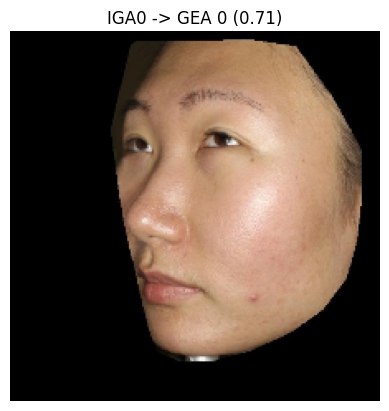

In [13]:
def iga_ke_gea(nama_iga: str) -> dict:
    info = LABEL_GEA.get(nama_iga, {"grade": None, "label": "tidak diketahui"})
    return {"iga": nama_iga, **info}


def prediksi_gambar(path_gambar: Path):
    img = tf.keras.utils.load_img(path_gambar, target_size=(UKURAN, UKURAN))
    arr = tf.keras.utils.img_to_array(img)[None, ...]
    skor = model_terbaik.predict(arr, verbose=0)[0]
    idx = int(np.argmax(skor))
    nama = nama_kelas[idx]
    hasil = iga_ke_gea(nama)
    hasil["confidence"] = float(skor[idx])
    hasil["skor"] = {nama_kelas[i]: float(skor[i]) for i in range(jumlah_kelas)}
    return img, hasil


print("Pemetaan kelas:")
for nama in nama_kelas:
    print(" ", iga_ke_gea(nama))

contoh = next(folder_dataset.joinpath("test").rglob("*.jpg"), None)
if contoh is None:
    contoh = next(folder_dataset.joinpath("test").rglob("*.png"), None)
if contoh is not None:
    gambar, hasil = prediksi_gambar(contoh)
    print("\nContoh berkas:", contoh)
    print(hasil)
    plt.imshow(gambar)
    plt.title("{0} -> GEA {1} ({2:.2f})".format(hasil["iga"], hasil["grade"], hasil["confidence"]))
    plt.axis("off")
    plt.show()


## 14. Ekspor TensorFlow Lite

File `machine-learning/laksamanaap/laksa_custom_cnn.tflite` siap dipakai untuk laporan (dan di-embed ke back-end/mobile).

**Input:** RGB `[1, 224, 224, 3]`, float32, piksel 0–255 (jangan dibagi 255 lagi).  
**Output:** Softmax sepanjang kelas IGA; ambil `argmax`, lalu petakan ke GEA.


In [14]:
model_ekspor = tf.keras.models.load_model(path_keras, compile=False)
bentuk_gambar = tuple(model_ekspor.input_shape[1:])

input_lite = tf.keras.Input(
    shape=bentuk_gambar, batch_size=1, dtype=tf.float32, name="gambar"
)
x_lite = input_lite
for layer in model_ekspor.layers:
    if isinstance(
        layer,
        (layers.InputLayer, layers.RandomFlip, layers.RandomRotation, layers.Dropout),
    ):
        continue
    if isinstance(layer, layers.BatchNormalization):
        x_lite = layer(x_lite, training=False)
    else:
        x_lite = layer(x_lite)

model_inferensi = tf.keras.Model(input_lite, x_lite, name="Laksa_CustomCNN_Inferensi")
converter = tf.lite.TFLiteConverter.from_keras_model(model_inferensi)
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]
tflite_model = converter.convert()

interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()
detail_in = interpreter.get_input_details()[0]
detail_out = interpreter.get_output_details()[0]

batch_uji, _ = next(iter(val_ds))
gambar_uji = np.asarray(batch_uji[:1], dtype=np.float32)
skor_keras = model_ekspor(gambar_uji, training=False).numpy()
interpreter.set_tensor(detail_in["index"], gambar_uji)
interpreter.invoke()
skor_lite = interpreter.get_tensor(detail_out["index"])
selisih = float(np.max(np.abs(skor_keras - skor_lite)))
assert int(skor_keras.argmax()) == int(skor_lite.argmax())

path_tflite.write_bytes(tflite_model)
metadata = {
    "input_shape": [1, *bentuk_gambar],
    "input_dtype": "float32",
    "color_mode": "RGB",
    "pixel_range": [0, 255],
    "normalization_in_model": True,
    "class_names": nama_kelas,
    "gea_mapping": {k: LABEL_GEA[k] for k in nama_kelas if k in LABEL_GEA},
    "output": "softmax_scores",
    "dataset": f"{ROBOFLOW_UNIVERSE_WORKSPACE}/{ROBOFLOW_PROJECT}/{ROBOFLOW_VERSION}",
    "tensorflow_version": tf.__version__,
    "max_abs_difference": selisih,
}
path_meta = path_tflite.with_name(path_tflite.stem + "_tflite.json")
path_meta.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print("TFLite:", path_tflite)
print("Ukuran: %.2f KB" % (path_tflite.stat().st_size / 1024))
print("Metadata:", path_meta)
print("Selisih skor Keras vs TFLite:", selisih)


INFO:tensorflow:Assets written to: C:\Users\laksa\AppData\Local\Temp\tmpge3cr2p0\assets


INFO:tensorflow:Assets written to: C:\Users\laksa\AppData\Local\Temp\tmpge3cr2p0\assets


Saved artifact at 'C:\Users\laksa\AppData\Local\Temp\tmpge3cr2p0'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 224, 224, 3), dtype=tf.float32, name='gambar')
Output Type:
  TensorSpec(shape=(1, 5), dtype=tf.float32, name=None)
Captures:
  1757021087248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1757021128128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1757021130240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1757021090592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1757021092880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1757021138336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1757021136400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1757021140272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1757021138160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1757021138864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1757021140448: Te

    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
